# Marca d'Água: rede neural para o risco de chuva forte

Global Solution 2026.2, FIAP. Redes Neurais Artificiais, Deep Learning e Algoritmos Genéticos.

Rafael Gonçalves (RM 569461) e Charles Augusto (RM 571908).

Este notebook usa o mesmo problema, o mesmo público e a mesma base do notebook de Machine Learning, mas com uma entrada diferente: em vez de atributos resumidos, a rede recebe a sequência hora a hora das últimas 72 horas. Ele compara um MLP com duas redes recorrentes (GRU e LSTM), treina, refina com regularização e busca de hiperparâmetros, avalia no período de teste e demonstra a aplicação com exemplos que a rede não viu no treino.

## 1. Problema e aplicação

Em Porto Alegre, o aviso de alagamento costuma chegar tarde ou por um canal que quem mora em área de risco não usa. O nó Marca d'Água (um ESP32 com sensores de nível, chuva, temperatura e umidade) avisa no próprio local, com LED e buzzer, mesmo sem internet. A rede neural acrescenta o que o nó sozinho não faz: estimar, a cada 6 horas, se a chuva acumulada nas próximas 72 horas vai passar de `LIMIAR_MM`.

Público impactado: moradores de áreas de risco (ilhas, Sarandi, Humaitá e vizinhas) e a Defesa Civil municipal. O contexto de uso inclui internet instável durante a enchente e parte da população sem smartphone, e por isso o aviso imediato continua sendo o do nó, que não depende deste modelo. A rede entra como um segundo sinal, de prazo mais longo.

Entrada: uma janela com as últimas 72 horas, uma linha por hora, com 6 variáveis (chuva, pressão, temperatura, umidade, vento e rajada), mais a posição no ano (seno e cosseno do dia). Saída: a probabilidade, de 0 a 1, de a chuva acumulada nas 72 horas seguintes ser maior ou igual a `LIMIAR_MM`. É uma classificação binária, e a probabilidade vira uma faixa de risco (baixo, atenção ou alerta).

Por que uma rede para sequências. O fenômeno tem ordem no tempo: pressão caindo por horas e umidade subindo contam diferente de os mesmos valores em ordem inversa. Uma rede recorrente lê a janela hora a hora e guarda um resumo do que viu. O MLP, de comparação, recebe a janela inteira de uma vez, sem noção de ordem além da posição de cada entrada.

## 2. Base de dados

Fonte: INMET, estação automática A801 (Porto Alegre), dados horários de 2014 a 2025, cerca de 105 mil linhas. São dados reais. O professor de Redes Neurais confirmou por escrito que a base pode ser usada (print em `docs/evidencias/rna-validacao-base-inmet-pedido-e-resposta.png`).

Por que esta base serve para a tarefa:
- É a mesma do notebook de ML e do restante do projeto, o que mantém a integração entre as disciplinas.
- É uma série regular, hora a hora, o que permite montar janelas de sequência sem inventar dado.
- Inclui eventos reais de chuva forte, entre eles os de 2023, 2024 e 2025, que ficam no período de teste.

Limitações: uma única estação, horários em UTC e lacunas medidas na seção 3. O alvo (chuva acumulada em 72 horas) aproxima o risco de alagamento e não o mede.

## 3. Carga e qualidade dos dados

As células de download, leitura e limpeza são as mesmas do notebook de ML. Os zips do INMET vão para `dados_inmet/` (fora do Git). Se o portal recusar o download, baixe os zips à mão e envie para essa pasta pelo painel de arquivos do Colab.

In [1]:
import os, re, zipfile, unicodedata, urllib.request, warnings, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             recall_score, precision_score)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
keras.utils.set_random_seed(SEED)
ANOS = range(2014, 2026)
ESTACAO = "A801"
PASTA = "dados_inmet"
URL = "https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"

JANELA_ALVO_H = 72
PASSO_AMOSTRA_H = 6
CORTE_TESTE = pd.Timestamp("2023-01-01")
LIMIAR_MM = 50          # o mesmo do notebook de ML

In [2]:
os.makedirs(PASTA, exist_ok=True)
falhas = []
for ano in ANOS:
    destino = f"{PASTA}/{ano}.zip"
    if os.path.exists(destino):
        continue
    try:
        req = urllib.request.Request(URL.format(ano=ano), headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=90) as r, open(destino, "wb") as f:
            f.write(r.read())
    except Exception as e:
        falhas.append((ano, str(e)[:70]))

presentes = [a for a in ANOS if os.path.exists(f"{PASTA}/{a}.zip")]
print("zips disponíveis:", presentes)
if falhas:
    print("falha no download:", falhas)
assert len(presentes) >= 8, "poucos anos carregados: baixe os zips à mão para dados_inmet/"

zips disponíveis: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [3]:
def sem_acento(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().upper()

# o nome das colunas muda um pouco de ano para ano (acentos, parênteses), então casa por trecho
def nome_curto(col):
    c = sem_acento(col)
    if c.startswith("DATA"): return "data"
    if c.startswith("HORA"): return "hora"
    if "PRECIPITACAO" in c: return "chuva_mm"
    if "NIVEL DA ESTACAO" in c: return "pressao_mb"
    if "BULBO SECO" in c: return "temp_c"
    if "PONTO DE ORVALHO" in c and "MAX" not in c and "MIN" not in c: return "orvalho_c"
    if "UMIDADE RELATIVA DO AR" in c: return "umid_pct"
    if "VENTO, VELOCIDADE" in c: return "vento_ms"
    if "VENTO, RAJADA" in c: return "rajada_ms"
    return None

def le_ano(caminho):
    with zipfile.ZipFile(caminho) as z:
        nomes = [n for n in z.namelist() if f"_{ESTACAO}_" in n.upper()]
        if not nomes:
            raise FileNotFoundError(f"estação {ESTACAO} não está em {caminho}")
        with z.open(nomes[0]) as f:
            df = pd.read_csv(f, sep=";", skiprows=8, encoding="latin-1",
                             decimal=",", na_values=["-9999", "-9999,0"],
                             dtype={0: str, 1: str})  # hora "0100" viraria o numero 100
    df = df.rename(columns={c: nome_curto(c) for c in df.columns})
    df = df[[c for c in df.columns if c is not None and isinstance(c, str)]]
    df = df.loc[:, ~df.columns.duplicated()]
    # data aparece como 2014/01/01 ou 2014-01-01, hora como 0000 ou 0000 UTC (sempre UTC)
    d = df["data"].astype(str).str.replace("/", "-", regex=False)
    h = df["hora"].astype(str).str.extract(r"(\d{2})")[0]
    df["dt"] = pd.to_datetime(d + " " + h + ":00", errors="coerce")
    return df.drop(columns=["data", "hora"])

bruto = pd.concat([le_ano(f"{PASTA}/{a}.zip") for a in presentes], ignore_index=True)
print(bruto.shape)
bruto.head()

(105192, 8)


,chuva_mm,pressao_mb,temp_c,orvalho_c,umid_pct,rajada_ms,vento_ms,dt
0,0.0,1001.3,25.3,20.1,73.0,3.6,1.0,2014-01-01 00:00:00
1,0.0,1001.5,24.6,20.7,79.0,2.2,0.0,2014-01-01 01:00:00
2,0.0,1001.1,24.8,20.7,78.0,1.8,0.5,2014-01-01 02:00:00
3,0.0,1000.7,24.2,20.6,80.0,2.5,1.0,2014-01-01 03:00:00
4,0.0,1000.7,24.4,21.1,82.0,2.3,0.5,2014-01-01 04:00:00


In [4]:
print("datas inválidas:", bruto["dt"].isna().sum())
print("registros duplicados no mesmo horário:", bruto["dt"].duplicated().sum())

bruto = bruto.dropna(subset=["dt"]).drop_duplicates("dt").set_index("dt").sort_index()
horario = bruto.reindex(pd.date_range(bruto.index.min(), bruto.index.max(), freq="h"))
horario.index.name = "dt"
print("horas esperadas:", len(horario), "| horas com registro:", len(bruto),
      "| horas ausentes na grade:", len(horario) - len(bruto))

limites = {"chuva_mm": (0, 150), "pressao_mb": (900, 1100), "temp_c": (-10, 50),
           "orvalho_c": (-20, 40), "umid_pct": (0, 100), "vento_ms": (0, 60), "rajada_ms": (0, 90)}
for col, (lo, hi) in limites.items():
    fora = ((horario[col] < lo) | (horario[col] > hi)).sum()
    if fora:
        print(f"{col}: {fora} valores fora de [{lo}, {hi}] viraram ausentes")
    horario.loc[(horario[col] < lo) | (horario[col] > hi), col] = np.nan

horario[list(limites)].describe().T.round(2)

datas inválidas: 0
registros duplicados no mesmo horário: 0
horas esperadas: 105192 | horas com registro: 105192 | horas ausentes na grade: 0


,count,mean,std,min,25%,50%,75%,max
chuva_mm,104654.0,0.19,1.16,0.0,0.0,0.0,0.0,47.6
pressao_mb,104654.0,1009.92,5.55,988.7,1006.0,1009.7,1013.6,1030.2
temp_c,104652.0,20.18,5.69,2.3,16.3,20.2,23.9,40.2
orvalho_c,104647.0,15.71,4.59,-3.4,12.8,16.2,19.2,27.1
umid_pct,104649.0,77.50,15.74,15.0,66.0,81.0,91.0,100.0
vento_ms,103000.0,1.45,0.89,0.0,0.8,1.3,2.0,7.9
rajada_ms,102954.0,4.71,2.55,0.0,2.7,4.4,6.3,33.2


Primeiras linhas da série horária e um trecho do evento de abril de 2024, que aparece de novo na demonstração:

In [5]:
CANAIS = ["chuva_mm", "pressao_mb", "temp_c", "umid_pct", "vento_ms", "rajada_ms"]
print(horario[CANAIS].head(5).round(1).to_string())
print()
print(horario.loc["2024-04-29 06:00":"2024-04-29 12:00", CANAIS].round(1).to_string())

                     chuva_mm  pressao_mb  temp_c  umid_pct  vento_ms  rajada_ms
dt                                                                              
2014-01-01 00:00:00       0.0      1001.3    25.3      73.0       1.0        3.6
2014-01-01 01:00:00       0.0      1001.5    24.6      79.0       0.0        2.2
2014-01-01 02:00:00       0.0      1001.1    24.8      78.0       0.5        1.8
2014-01-01 03:00:00       0.0      1000.7    24.2      80.0       1.0        2.5
2014-01-01 04:00:00       0.0      1000.7    24.4      82.0       0.5        2.3

                     chuva_mm  pressao_mb  temp_c  umid_pct  vento_ms  rajada_ms
dt                                                                              
2024-04-29 06:00:00       0.0      1006.1    19.3      87.0       1.1        6.0
2024-04-29 07:00:00       0.0      1005.6    19.5      87.0       1.3        3.7
2024-04-29 08:00:00       0.0      1005.5    19.6      86.0       0.9        3.6
2024-04-29 09:00:00       0

### Alvo

O alvo é o mesmo do notebook de ML: o acumulado de chuva em (t, t + 72 h], rotulado como evento quando passa de `LIMIAR_MM`. Um rótulo só vale se pelo menos 90% das horas da janela futura foram observadas.

count    17352.0
mean        13.4
std         22.7
min          0.0
25%          0.0
50%          3.0
75%         18.0
max        280.4
Name: chuva_mm, dtype: float64


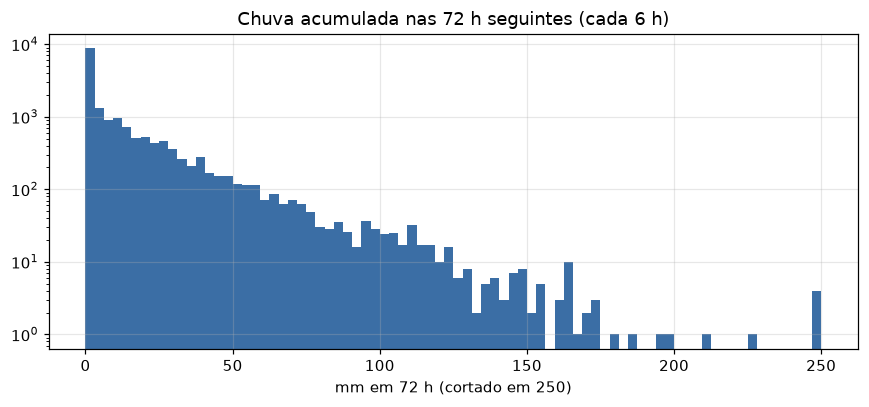

In [6]:
chuva = horario["chuva_mm"]
# acumulado FUTURO de 72 h em (t, t+72h]: é o que o modelo tenta prever
def soma_futura(chuva, janela=JANELA_ALVO_H):
    idx = pd.api.indexers.FixedForwardWindowIndexer(window_size=janela)
    soma = chuva.fillna(0).rolling(idx, min_periods=1).sum().shift(-1)
    n_obs = chuva.notna().astype(float).rolling(idx, min_periods=1).sum().shift(-1)
    # janela com menos de 90% das horas observadas não vale como rótulo
    return soma.where(n_obs >= 0.9 * janela)

futura = soma_futura(chuva)
cada_6h = futura[futura.index.hour % PASSO_AMOSTRA_H == 0].dropna()
print(cada_6h.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(cada_6h.clip(upper=250), bins=80, color="#3b6ea5")
ax.set_yscale("log")
ax.set_title("Chuva acumulada nas 72 h seguintes (cada 6 h)")
ax.set_xlabel("mm em 72 h (cortado em 250)")
plt.tight_layout(); plt.show()

## 4. Preparação dos dados

Decisões desta etapa:

- **Janela de 72 horas.** Igual ao horizonte do alvo. Uma janela mais curta perderia o começo do ciclo de pressão e umidade. Uma mais longa aumenta o custo e o risco de decorar o treino, e o notebook de ML já mostrou que a chuva dos últimos 7 dias traz pouca informação a mais.
- **Uma amostra a cada 6 horas**, como no ML, para não repetir quase a mesma janela hora após hora.
- **Ausentes.** Chuva ausente vira 0, como já acontece na soma do alvo. As outras variáveis repetem o último valor por até 6 horas, e o que sobrar vira a média do período de ajuste (zero depois de padronizar). Uma janela com mais de 20% de valores ausentes sai da base.
- **Escala.** A chuva passa por `log1p`, porque é muito assimétrica (muitas horas secas e poucas horas violentas). Depois, todas as variáveis são padronizadas com a média e o desvio do período de ajuste, e os valores são cortados em ±5 desvios. O corte é uma lição do notebook de ML: uma hora com 25,8 mm fez o modelo linear extrapolar e gerar um pico isolado de probabilidade. A rede não deve explodir com uma entrada fora do que viu.
- **Divisão temporal, sem embaralhar.** Ajuste até junho de 2021, validação de julho de 2021 a dezembro de 2022 (para early stopping e escolha de hiperparâmetros) e teste de 2023 a 2025. Entre as partes ficam 72 horas de folga, porque o rótulo de uma amostra olha 72 horas para a frente.

In [7]:
JANELA_H = 72
h = horario[CANAIS]
falta = h.isna().to_numpy()

bruto = h.copy()
bruto["chuva_mm"] = bruto["chuva_mm"].fillna(0)
bruto = bruto.ffill(limit=6)

# fração de ausentes na janela das 72 h que terminam em cada hora
frac_falta = pd.DataFrame(falta).rolling(JANELA_H).mean().to_numpy().mean(axis=1)
valido = ((h.index.hour % PASSO_AMOSTRA_H == 0) & futura.notna().to_numpy()
          & (np.arange(len(h)) >= JANELA_H - 1) & (frac_falta <= 0.2))
pos = np.flatnonzero(valido)
datas = h.index[pos]
y = (futura.to_numpy()[pos] >= LIMIAR_MM).astype("float32")

VAL_INI = pd.Timestamp("2021-07-01")
FOLGA = pd.Timedelta(hours=JANELA_ALVO_H)
m_teste = datas >= CORTE_TESTE
m_treino = datas <= CORTE_TESTE - FOLGA
m_val = m_treino & (datas >= VAL_INI)
m_fit = datas <= VAL_INI - FOLGA

# escala aprendida só no período de ajuste
horas_fit = bruto.index <= VAL_INI - FOLGA
cru = bruto.to_numpy(dtype="float64").copy()
cru[:, 0] = np.log1p(cru[:, 0])
mu = np.nanmean(cru[horas_fit], axis=0)
dp = np.nanstd(cru[horas_fit], axis=0)
esc = np.clip((cru - mu) / dp, -5, 5)
esc = np.nan_to_num(esc, nan=0.0).astype("float32")

idx = pos[:, None] + np.arange(-JANELA_H + 1, 1)
X = esc[idx]                                     # (amostras, 72 horas, 6 variáveis)
doy = datas.dayofyear.to_numpy()
S = np.column_stack([np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)]).astype("float32")

X_fit, S_fit, y_fit = X[m_fit], S[m_fit], y[m_fit]
X_val, S_val, y_val = X[m_val], S[m_val], y[m_val]
X_teste, S_teste, y_teste = X[m_teste], S[m_teste], y[m_teste]

resumo = pd.DataFrame({
    "amostras": [m_fit.sum(), m_val.sum(), m_teste.sum()],
    "eventos": [int(y_fit.sum()), int(y_val.sum()), int(y_teste.sum())],
    "taxa": [f"{y_fit.mean():.1%}", f"{y_val.mean():.1%}", f"{y_teste.mean():.1%}"],
    "início": [datas[m_fit].min().date(), datas[m_val].min().date(), datas[m_teste].min().date()],
    "fim": [datas[m_fit].max().date(), datas[m_val].max().date(), datas[m_teste].max().date()],
}, index=["ajuste", "validação", "teste"])
print(resumo)
print("formato da entrada:", X.shape, "| sazonalidade:", S.shape)

checks = {
    "ajuste termina 72 h antes da validação": datas[m_fit].max() + FOLGA <= datas[m_val].min(),
    "validação termina 72 h antes do teste": datas[m_val].max() + FOLGA <= datas[m_teste].min(),
    "a escala usa só horas do ajuste": bruto.index[horas_fit].max() <= VAL_INI - FOLGA,
    "nenhuma entrada passa de 5 desvios": float(np.abs(X).max()) <= 5.0,
    "a janela termina na hora da amostra": bool(np.all(idx[:, -1] == pos)),
}
for nome, ok_ in checks.items():
    print("ok " if ok_ else "FALHOU", nome)
assert all(checks.values())

           amostras  eventos  taxa      início         fim
ajuste        10705      702  6.6%  2014-01-04  2021-06-28
validação      2185      124  5.7%  2021-07-01  2022-12-29
teste          4162      351  8.4%  2023-01-01  2025-12-29
formato da entrada: (17074, 72, 6) | sazonalidade: (17074, 2)
ok  ajuste termina 72 h antes da validação
ok  validação termina 72 h antes do teste
ok  a escala usa só horas do ajuste
ok  nenhuma entrada passa de 5 desvios
ok  a janela termina na hora da amostra


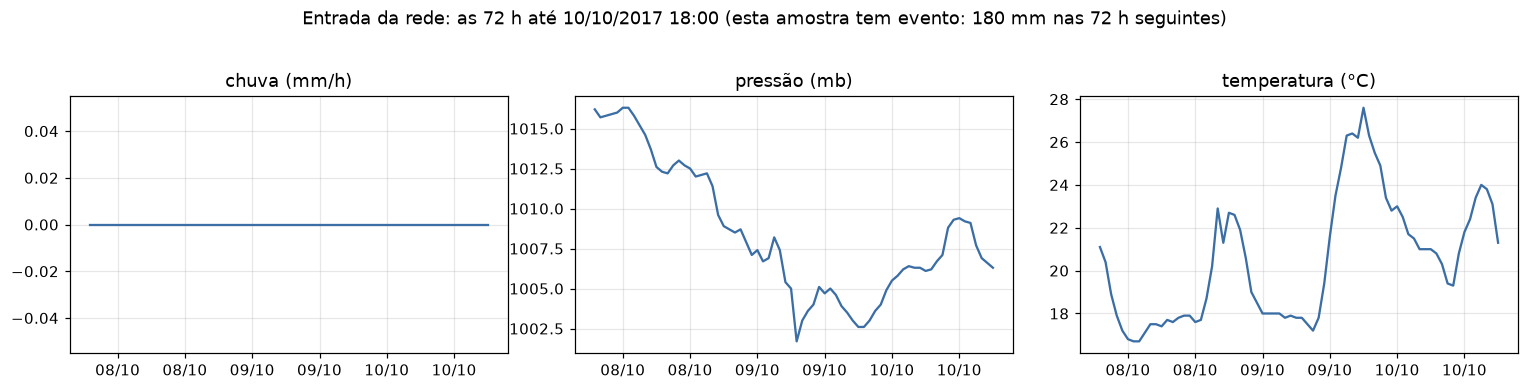

In [8]:
# um exemplo de janela: o início do maior episódio do ajuste ou da validação (antes do teste)
cand = np.flatnonzero(m_treino & (y == 1))
k = cand[np.argmax(futura.to_numpy()[pos][cand])]
fim = datas[k]
trecho = bruto.loc[fim - pd.Timedelta(hours=JANELA_H - 1):fim]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4), sharex=True)
for ax, col, nome in zip(axs, ["chuva_mm", "pressao_mb", "temp_c"], ["chuva (mm/h)", "pressão (mb)", "temperatura (°C)"]):
    ax.plot(trecho.index, trecho[col], color="#3b6ea5"); ax.set_title(nome)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.suptitle(f"Entrada da rede: as 72 h até {fim:%d/%m/%Y %H:%M} (esta amostra tem evento: {futura.to_numpy()[pos][k]:.0f} mm nas 72 h seguintes)", y=1.03)
plt.tight_layout(); plt.show()

## 5. Arquiteturas

Três redes, todas com duas entradas (a janela de 72 horas e a posição no ano) e uma saída sigmoide com a probabilidade do evento.

O MLP achata a janela em 432 números, junta os 2 da sazonalidade e passa por duas camadas densas com ReLU. Serve de comparação: tem os mesmos dados, mas não lê a janela em ordem. A GRU e a LSTM leem a janela hora a hora e guardam um estado interno que resume o que viram. No fim da janela, esse estado é juntado com a sazonalidade e passa por uma camada densa pequena antes da saída. A GRU tem duas portas e menos parâmetros. A LSTM tem uma célula de memória separada e três portas, e costuma ser testada em sequências maiores. Em 72 passos as duas devem render parecido, e o experimento vai dizer.

O bias da saída começa em `log(p / (1 - p))`, onde `p` é a taxa de eventos do ajuste. Assim, a rede começa prevendo a frequência de eventos e não 50%, e o treino não gasta as primeiras épocas só aprendendo a ser pessimista. A função de perda é a entropia cruzada binária, sem peso de classe, porque a probabilidade que sai da rede precisa fazer sentido como probabilidade para virar faixa de risco.

In [9]:
taxa_fit = float(y_fit.mean())

def monta(arq, unidades=32, dropout=0.0, lr=1e-3):
    janela = keras.Input((JANELA_H, len(CANAIS)), name="janela")
    estacao = keras.Input((2,), name="estacao")
    if arq == "MLP":
        x = layers.Concatenate()([layers.Flatten()(janela), estacao])
        x = layers.Dense(unidades, activation="relu")(x)
        x = layers.Dropout(dropout)(x)
        x = layers.Dense(unidades // 2, activation="relu")(x)
        x = layers.Dropout(dropout)(x)
    else:
        recorrente = layers.GRU if arq == "GRU" else layers.LSTM
        x = recorrente(unidades)(janela)
        x = layers.Concatenate()([x, estacao])
        x = layers.Dense(unidades // 2, activation="relu")(x)
        x = layers.Dropout(dropout)(x)
    bias = keras.initializers.Constant(np.log(taxa_fit / (1 - taxa_fit)))
    saida = layers.Dense(1, activation="sigmoid", bias_initializer=bias)(x)
    modelo = keras.Model([janela, estacao], saida, name=arq)
    modelo.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                   metrics=[keras.metrics.AUC(name="pr_auc", curve="PR")])
    return modelo

for arq, un in [("MLP", 64), ("GRU", 32), ("LSTM", 32)]:
    m = monta(arq, un)
    print(f"{arq}: {m.count_params():,} parâmetros".replace(",", "."))
monta("GRU", 32).summary()

MLP: 29.953 parâmetros
GRU: 4.417 parâmetros
LSTM: 5.569 parâmetros


Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ janela (InputLayer) │ (None, 72, 6)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 32)        │      3,840 │ janela[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ estacao             │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 34)        │          0 │ gru_1[0][0],      │
│ (Concatenate)       │                   │            │ estacao[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 16)        │        560 │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 16)        │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 1)         │         17 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,417 (17.25 KB)

 Trainable params: 4,417 (17.25 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Treinamento

Parâmetros desta primeira rodada, sem regularização: otimizador Adam, taxa de aprendizado 0,001, lotes de 128 amostras e 30 épocas, com unidades de 64 (MLP) e 32 (GRU e LSTM). A semente é fixa (`SEED = 42`). Ao fim de cada época a rede é avaliada na validação, e o que se acompanha é a perda e a PR-AUC, a área sob a curva de precisão por recall, que é a métrica que importa com 7% de eventos.

MLP: 15 s


GRU: 64 s


LSTM: 58 s


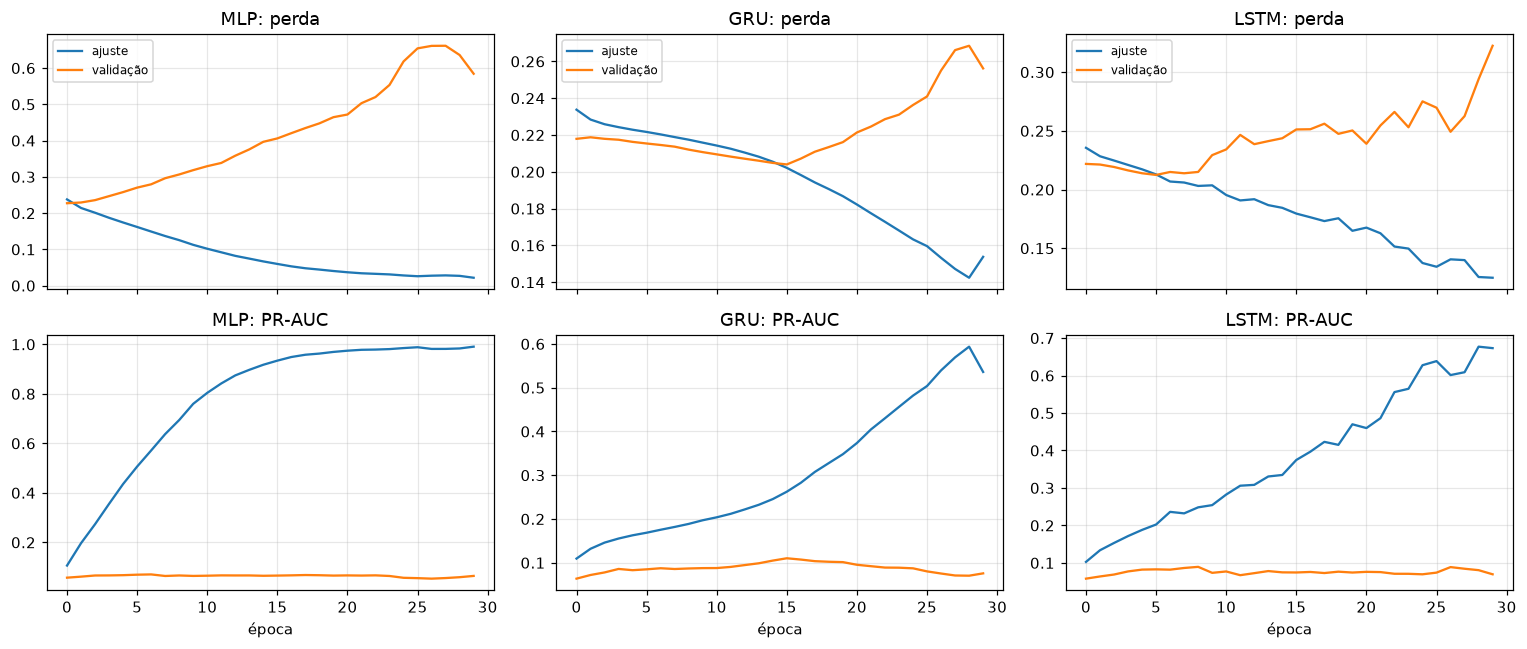

,PR-AUC de ajuste na última época,PR-AUC de validação na última época,melhor PR-AUC de validação,época desse melhor,época da menor perda de validação
MLP,0.991,0.064,0.071,7.0,1.0
GRU,0.536,0.076,0.110,16.0,16.0
LSTM,0.673,0.070,0.089,9.0,6.0


In [10]:
EPOCAS = 30
BATCH = 128

def treina(arq, seed=SEED, epocas=EPOCAS, batch=BATCH, parada=None, **kw):
    keras.utils.set_random_seed(seed)
    modelo = monta(arq, **kw)
    cbs = []
    if parada:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=parada,
                                                 restore_best_weights=True))
    hist = modelo.fit([X_fit, S_fit], y_fit, validation_data=([X_val, S_val], y_val),
                      epochs=epocas, batch_size=batch, callbacks=cbs, verbose=0)
    return modelo, hist.history

def prob(modelo, Xj, Sj):
    return modelo.predict([Xj, Sj], batch_size=1024, verbose=0).ravel()

def ap_val(modelo):
    return average_precision_score(y_val, prob(modelo, X_val, S_val))

base = {}
for arq, un in [("MLP", 64), ("GRU", 32), ("LSTM", 32)]:
    t0 = time.time()
    m, hist = treina(arq, unidades=un)
    base[arq] = hist
    print(f"{arq}: {time.time() - t0:.0f} s")

fig, axs = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for j, arq in enumerate(base):
    hist = base[arq]
    axs[0, j].plot(hist["loss"], label="ajuste"); axs[0, j].plot(hist["val_loss"], label="validação")
    axs[0, j].set_title(f"{arq}: perda"); axs[0, j].legend(fontsize=8)
    axs[1, j].plot(hist["pr_auc"], label="ajuste"); axs[1, j].plot(hist["val_pr_auc"], label="validação")
    axs[1, j].set_title(f"{arq}: PR-AUC"); axs[1, j].set_xlabel("época")
plt.tight_layout(); plt.show()

linhas = {}
for arq, hist in base.items():
    vp = np.array(hist["val_pr_auc"]); vl = np.array(hist["val_loss"])
    linhas[arq] = {"PR-AUC de ajuste na última época": hist["pr_auc"][-1],
                   "PR-AUC de validação na última época": vp[-1],
                   "melhor PR-AUC de validação": vp.max(), "época desse melhor": int(vp.argmax()) + 1,
                   "época da menor perda de validação": int(vl.argmin()) + 1}
pd.DataFrame(linhas).T.round(3)

### Leitura do primeiro treino

Sem regularização, as três redes decoram o ajuste. No MLP, a PR-AUC de ajuste chega a 0,99 enquanto a de validação fica em 0,06, e a perda de validação é a menor logo na primeira época e depois só sobe. Com quase 30 mil parâmetros para 10.705 amostras, ele memoriza. A GRU e a LSTM têm bem menos parâmetros (4.417 e 5.569) e sobreajustam mais devagar: a perda de validação da GRU começa a subir perto da época 16, e a melhor PR-AUC de validação dela (0,110) está nessa época, contra 0,076 na época 30. A LSTM tem a menor perda de validação na época 6.

Há um segundo ponto, menos visível. A taxa de eventos na validação é 5,7%, e um modelo que sempre responde essa taxa tem perda de 0,218. A melhor perda de validação da GRU, lida no gráfico, fica perto de 0,20, menos de 10% abaixo disso. O sinal nos dados é fraco, como já era no notebook de ML, e nenhuma rede muda isso. O que o treino pede é parar cedo, que é o que o early stopping faz.

## 7. Refinamento e otimização

Duas frentes, sempre medidas na validação (o teste continua intocado):

1. Regularização: early stopping, que para o treino quando a PR-AUC de validação deixa de melhorar por 8 épocas e devolve os pesos da melhor época, e dropout de 0,3 nas camadas densas.
2. Hiperparâmetros: taxa de aprendizado, número de unidades, tamanho do lote e taxa de dropout, em uma busca aleatória.

Como uma rede treinada uma vez depende da semente, cada configuração da primeira frente roda com 3 sementes e aparece com média e desvio. A nota de cada rodada é a PR-AUC de validação do modelo que sobra no fim do treino: os pesos da última época na versão padrão, os pesos da melhor época nas versões com early stopping.

In [11]:
SEMENTES = [42, 43, 44]
VARIANTES = {
    "padrão (30 épocas)": dict(parada=None, dropout=0.0),
    "early stopping": dict(parada=8, dropout=0.0),
    "early stopping + dropout 0,3": dict(parada=8, dropout=0.3),
}
UNID = {"MLP": 64, "GRU": 32, "LSTM": 32}

reg = {}
t0 = time.time()
for arq in UNID:
    for nome, cfg in VARIANTES.items():
        notas, epocas, hists = [], [], []
        for s in SEMENTES:
            m, hist = treina(arq, seed=s, unidades=UNID[arq], **cfg)
            notas.append(ap_val(m)); epocas.append(len(hist["loss"])); hists.append(hist)
        reg[(arq, nome)] = {"notas": notas, "epocas": epocas, "hists": hists}
print(f"{time.time() - t0:.0f} s")

tab_reg = pd.DataFrame({
    k: {"PR-AUC de validação (média)": np.mean(v["notas"]), "desvio entre sementes": np.std(v["notas"]),
        "épocas treinadas (média)": np.mean(v["epocas"])} for k, v in reg.items()}).T
tab_reg.index.names = ["rede", "variante"]
tab_reg.round(3)

873 s


PR-AUC de validação (média)  desvio entre sementes  épocas treinadas (média)
rede variante                                                                                                  
MLP  padrão (30 épocas)                                  0.068                  0.010                    30.000
     early stopping                                      0.075                  0.004                    20.667
     early stopping + dropout 0,3                        0.084                  0.003                    22.667
GRU  padrão (30 épocas)                                  0.070                  0.007                    30.000
     early stopping                                      0.095                  0.013                    22.000
     early stopping + dropout 0,3                        0.084                  0.003                    15.000
LSTM padrão (30 épocas)                                  0.070                  0.006                    30.000
     early stopping                                      0.083                  0.006                    20.000
     early stopping + dropout 0,3                        0.087                  0.006                    18.667

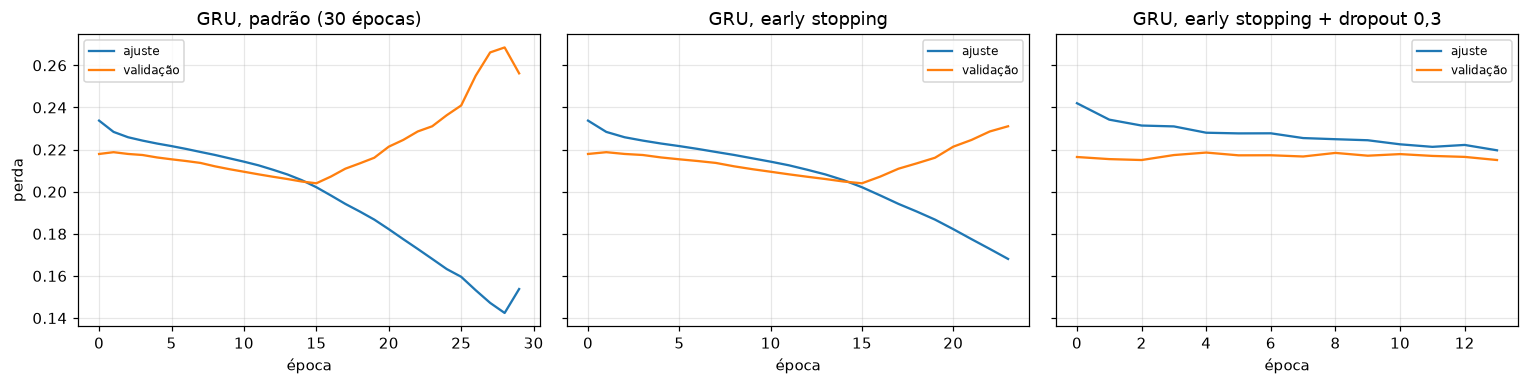

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (nome, cfg) in zip(axs, VARIANTES.items()):
    hist = reg[("GRU", nome)]["hists"][0]
    ax.plot(hist["loss"], label="ajuste"); ax.plot(hist["val_loss"], label="validação")
    ax.set_title(f"GRU, {nome}"); ax.set_xlabel("época"); ax.legend(fontsize=8)
axs[0].set_ylabel("perda")
plt.tight_layout(); plt.show()

### Leitura da regularização

O early stopping melhora a PR-AUC de validação nas três redes: de 0,068 para 0,075 no MLP, de 0,070 para 0,095 na GRU e de 0,070 para 0,083 na LSTM. O dropout de 0,3 acrescenta um pouco no MLP (0,084) e na LSTM (0,087) e não ajuda a GRU (0,084, abaixo dos 0,095 só com early stopping). Os desvios entre sementes vão de 0,003 a 0,013, então a ordem entre as versões regularizadas (0,084, 0,084, 0,087 e 0,095) cabe no ruído. O que se sustenta é a distância entre as versões padrão e as regularizadas, de 0,01 a 0,025.

As curvas da GRU mostram o mecanismo. Sem regularização, a perda de validação sobe a partir da época 16 e a de ajuste continua caindo. Com early stopping, o treino termina antes de a distância aumentar tanto. Com dropout, as curvas de ajuste e validação ficam próximas e quase planas, perto de 0,22, e a rede aprende devagar: o treino para depois de cerca de 14 épocas.

### Busca de hiperparâmetros

Para cada arquitetura, 6 configurações sorteadas (com a mesma semente de sorteio) de um espaço pequeno, todas com early stopping, treinadas uma vez cada. A melhor pela PR-AUC de validação é retreinada com as 3 sementes. Um espaço pequeno é suficiente aqui: o ganho esperado é modesto, e uma busca grande sobre uma validação de 124 eventos acabaria ajustando ruído.

In [13]:
ESPACO = {"lr": [3e-4, 1e-3, 3e-3, 1e-2], "unidades": [16, 32, 64], "batch": [64, 128, 256], "dropout": [0.1, 0.3, 0.5]}
rng = np.random.default_rng(SEED)
N_BUSCA = 6

busca = {}
melhor = {}
t0 = time.time()
for arq in UNID:
    linhas = []
    for _ in range(N_BUSCA):
        cfg = {k: v[rng.integers(len(v))] for k, v in ESPACO.items()}
        m, hist = treina(arq, seed=SEED, parada=8, **cfg)
        linhas.append({**cfg, "épocas": len(hist["loss"]), "PR-AUC de validação": ap_val(m)})
    busca[arq] = pd.DataFrame(linhas).sort_values("PR-AUC de validação", ascending=False).reset_index(drop=True)
    melhor[arq] = {k: busca[arq].loc[0, k] for k in ESPACO}
    melhor[arq]["unidades"] = int(melhor[arq]["unidades"]); melhor[arq]["batch"] = int(melhor[arq]["batch"])
print(f"{time.time() - t0:.0f} s")
for arq in busca:
    print(arq); print(busca[arq].round(4).to_string(index=False)); print()

495 s
MLP
    lr  unidades  batch  dropout  épocas  PR-AUC de validação
0.0030        64    256      0.5      30               0.0817
0.0003        64    128      0.3      30               0.0779
0.0010        64     64      0.5      29               0.0777
0.0030        16    256      0.3      25               0.0766
0.0030        32     64      0.5       9               0.0559
0.0003        16    128      0.5      14               0.0497

GRU
    lr  unidades  batch  dropout  épocas  PR-AUC de validação
0.0100        32    128      0.5      11               0.0975
0.0003        64    128      0.5      30               0.0946
0.0003        64    256      0.3      20               0.0906
0.0030        32    128      0.1      13               0.0898
0.0100        64     64      0.3      10               0.0760
0.0003        32    256      0.1      12               0.0649

LSTM
    lr  unidades  batch  dropout  épocas  PR-AUC de validação
0.0030        64    256      0.1      11         

In [14]:
final = {}
t0 = time.time()
for arq in UNID:
    cfg = melhor[arq]
    modelos, notas = [], []
    for s in SEMENTES:
        m, hist = treina(arq, seed=s, parada=8, **cfg)
        modelos.append(m); notas.append(ap_val(m))
    final[arq] = {"modelos": modelos, "notas_val": notas}
print(f"{time.time() - t0:.0f} s")

comp = {}
for arq in UNID:
    comp[arq] = {
        "padrão": np.mean(reg[(arq, "padrão (30 épocas)")]["notas"]),
        "early stopping": np.mean(reg[(arq, "early stopping")]["notas"]),
        "early stopping + dropout": np.mean(reg[(arq, "early stopping + dropout 0,3")]["notas"]),
        "hiperparâmetros ajustados": np.mean(final[arq]["notas_val"]),
        "desvio (ajustados)": np.std(final[arq]["notas_val"])}
print("PR-AUC de validação, média de 3 sementes")
pd.DataFrame(comp).T.round(3)

263 s
PR-AUC de validação, média de 3 sementes


,padrão,early stopping,early stopping + dropout,hiperparâmetros ajustados,desvio (ajustados)
MLP,0.068,0.075,0.084,0.076,0.004
GRU,0.070,0.095,0.084,0.094,0.011
LSTM,0.070,0.083,0.087,0.097,0.009


### Leitura da busca de hiperparâmetros

A busca não trouxe um ganho claro. O MLP ajustado (0,076) ficou abaixo do MLP com dropout de 0,3 e early stopping nos hiperparâmetros padrão (0,084). A escolha saiu de uma rodada com uma semente, e a nota de uma rodada oscila mais do que a distância entre configurações: os seis candidatos do MLP vão de 0,050 a 0,082. A GRU ajustada (0,094) empata com a GRU só com early stopping (0,095), e a LSTM sobe de 0,087 para 0,097, dentro do desvio (0,009). Os dois melhores candidatos de cada arquitetura têm taxas de aprendizado muito diferentes (GRU com 0,01 e 0,0003, LSTM com 0,003 e 0,001), sinal de uma superfície de busca plana.

O que a busca confirma é que regularizar importa mais do que o ajuste fino. Nenhuma versão passa de 0,10 de PR-AUC na validação, contra 0,057 do acaso. Há ainda um cuidado: essas notas são otimistas, porque a validação serviu para escolher e para reportar. A medida limpa é a do teste, na próxima seção.

## 8. Avaliação no teste (2023 a 2025)

O teste é usado agora, uma vez, com as redes já fechadas. Cada arquitetura entra como a média das previsões das 3 sementes (um conjunto pequeno de redes), o que reduz a dependência de uma semente de sorte. Para saber se a rede recorrente justifica o custo, entram três referências: o modelo sem informação, a persistência (se choveu `LIMIAR_MM` ou mais nas últimas 72 horas, repete) e uma regressão logística sobre a mesma entrada da rede, escolhida pela validação.

A PR-AUC vem com intervalo de confiança de 95% por bootstrap em blocos mensais, como no notebook de ML. Recall e precisão saem de um limiar escolhido só com a validação (o maior que captura 70% dos eventos), para a comparação não depender de olhar o teste.

In [15]:
def ensemble(arq, Xj, Sj):
    return np.mean([prob(m, Xj, Sj) for m in final[arq]["modelos"]], axis=0)

p_val = {a: ensemble(a, X_val, S_val) for a in UNID}
p_teste = {a: ensemble(a, X_teste, S_teste) for a in UNID}
por_semente = {a: [average_precision_score(y_teste, prob(m, X_teste, S_teste)) for m in final[a]["modelos"]] for a in UNID}

# referências
Xf = lambda Xj, Sj: np.hstack([Xj.reshape(len(Xj), -1), Sj])
melhor_c, melhor_nota = None, -1
for c in [0.0003, 0.001, 0.003, 0.01, 0.03]:
    lr = LogisticRegression(C=c, max_iter=3000).fit(Xf(X_fit, S_fit), y_fit)
    nota = average_precision_score(y_val, lr.predict_proba(Xf(X_val, S_val))[:, 1])
    if nota > melhor_nota: melhor_c, melhor_nota = c, nota
lr = LogisticRegression(C=melhor_c, max_iter=3000).fit(Xf(X_fit, S_fit), y_fit)
p_val["Regressão logística (janela)"] = lr.predict_proba(Xf(X_val, S_val))[:, 1]
p_teste["Regressão logística (janela)"] = lr.predict_proba(Xf(X_teste, S_teste))[:, 1]

chuva72 = bruto["chuva_mm"].rolling(JANELA_H).sum().to_numpy()[pos]
p_val["Persistência 72 h"] = chuva72[m_val] / (chuva72[m_val] + LIMIAR_MM)
p_teste["Persistência 72 h"] = chuva72[m_teste] / (chuva72[m_teste] + LIMIAR_MM)
p_val["Sem informação"] = np.full(m_val.sum(), y_fit.mean())
p_teste["Sem informação"] = np.full(m_teste.sum(), y_fit.mean())

# intervalo de confiança por blocos mensais, com os mesmos sorteios para todos
meses = datas[m_teste].to_period("M")
blocos = [np.flatnonzero(meses == mm) for mm in meses.unique()]
rng2 = np.random.default_rng(SEED)
sorteios = [rng2.integers(0, len(blocos), len(blocos)) for _ in range(500)]
def ic_pr(p):
    notas = []
    for s in sorteios:
        ix = np.concatenate([blocos[i] for i in s])
        if y_teste[ix].sum() > 0:
            notas.append(average_precision_score(y_teste[ix], p[ix]))
    return np.percentile(notas, [2.5, 97.5])

ordem = ["Sem informação", "Persistência 72 h", "Regressão logística (janela)", "MLP", "GRU", "LSTM"]
linhas = {}
for nome in ordem:
    lo, hi = ic_pr(p_teste[nome])
    linha = {"PR-AUC validação": average_precision_score(y_val, p_val[nome]),
             "PR-AUC teste": average_precision_score(y_teste, p_teste[nome]),
             "IC 95% do teste": f"{lo:.3f} a {hi:.3f}",
             "ROC-AUC teste": roc_auc_score(y_teste, p_teste[nome])}
    if nome in por_semente:
        linha["teste por semente (média ± desvio)"] = f"{np.mean(por_semente[nome]):.3f} ± {np.std(por_semente[nome]):.3f}"
    linhas[nome] = linha
tab_teste = pd.DataFrame(linhas).T
num = ["PR-AUC validação", "PR-AUC teste", "ROC-AUC teste"]
tab_teste[num] = tab_teste[num].astype(float).round(3)
print(f"teste: {int(y_teste.sum())} eventos em {len(y_teste)} amostras (taxa {y_teste.mean():.3f}) | C da regressão logística: {melhor_c}")
tab_teste.fillna("")

teste: 351 eventos em 4162 amostras (taxa 0.084) | C da regressão logística: 0.03


,PR-AUC validação,PR-AUC teste,IC 95% do teste,ROC-AUC teste,teste por semente (média ± desvio)
Sem informação,0.057,0.084,0.052 a 0.120,0.500,
Persistência 72 h,0.056,0.120,0.073 a 0.171,0.593,
Regressão logística (janela),0.075,0.194,0.126 a 0.271,0.682,
MLP,0.074,0.189,0.103 a 0.302,0.681,0.180 ± 0.004
GRU,0.114,0.161,0.101 a 0.226,0.708,0.175 ± 0.040
LSTM,0.101,0.150,0.086 a 0.233,0.662,0.147 ± 0.026


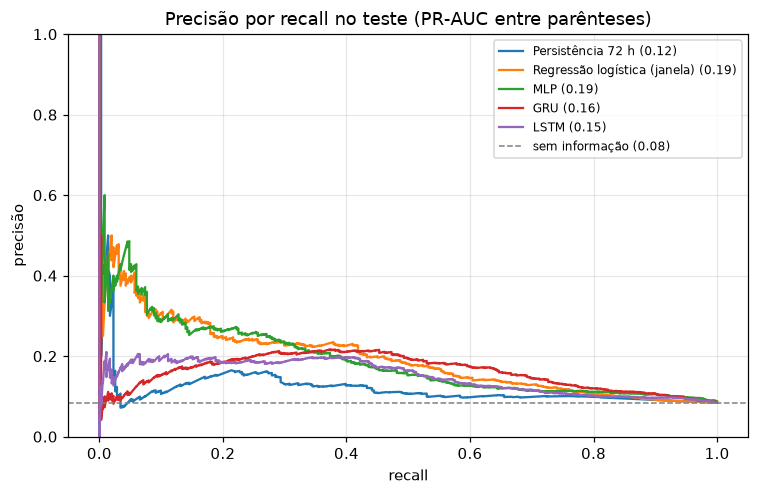

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.6))
for nome in ["Persistência 72 h", "Regressão logística (janela)", "MLP", "GRU", "LSTM"]:
    prec, rec, _ = precision_recall_curve(y_teste, p_teste[nome])
    ax.plot(rec, prec, label=f"{nome} ({average_precision_score(y_teste, p_teste[nome]):.2f})")
ax.axhline(y_teste.mean(), color="gray", ls="--", lw=1, label=f"sem informação ({y_teste.mean():.2f})")
ax.set_xlabel("recall"); ax.set_ylabel("precisão"); ax.set_ylim(0, 1)
ax.set_title("Precisão por recall no teste (PR-AUC entre parênteses)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [17]:
RECALL_ALVO = 0.70

def limiar_do_recall(pv):
    prec, rec, thr = precision_recall_curve(y_val, pv)
    return thr[rec[:-1] >= RECALL_ALVO].max()

linhas = {}
for nome in ["Persistência 72 h", "Regressão logística (janela)", "MLP", "GRU", "LSTM"]:
    lim = limiar_do_recall(p_val[nome])
    b = p_teste[nome] >= lim
    linhas[nome] = {"limiar (da validação)": lim, "recall no teste": recall_score(y_teste, b),
                    "precisão no teste": precision_score(y_teste, b, zero_division=0), "amostras sinalizadas": b.mean()}
pd.DataFrame(linhas).T.round(3)

,limiar (da validação),recall no teste,precisão no teste,amostras sinalizadas
Persistência 72 h,0.000,1.000,0.084,1.000
Regressão logística (janela),0.044,0.761,0.118,0.545
MLP,0.042,0.795,0.112,0.601
GRU,0.039,0.812,0.119,0.574
LSTM,0.041,0.698,0.117,0.505


In [18]:
# estabilidade por ano: a nota do teste vem de poucos episódios, então o ano a ano mostra o quanto oscila
anos = datas[m_teste].year
linhas = {}
for a in sorted(set(anos)):
    mk = anos == a
    linhas[a] = {"amostras": int(mk.sum()), "eventos": int(y_teste[mk].sum()), "taxa": y_teste[mk].mean()}
    for nome in ["Regressão logística (janela)", "MLP", "GRU", "LSTM"]:
        linhas[a][f"PR-AUC {nome}"] = average_precision_score(y_teste[mk], p_teste[nome][mk])
pd.DataFrame(linhas).T.round(3)

,amostras,eventos,taxa,PR-AUC Regressão logística (janela),PR-AUC MLP,PR-AUC GRU,PR-AUC LSTM
2023,1434.0,142.0,0.099,0.195,0.251,0.190,0.182
2024,1464.0,117.0,0.080,0.171,0.110,0.126,0.108
2025,1264.0,92.0,0.073,0.305,0.297,0.188,0.242


### Leitura da avaliação

As redes não ganham da regressão logística sobre a mesma janela. No teste, a PR-AUC é 0,194 para a regressão logística, 0,189 para o MLP, 0,161 para a GRU e 0,150 para a LSTM, contra 0,084 do acaso e 0,120 da persistência. Os intervalos de 95% se sobrepõem quase por inteiro (0,126 a 0,271 da logística, 0,086 a 0,233 da LSTM), então o teste não separa os quatro. O que se pode afirmar é que nenhuma rede recorrente mostra vantagem sobre o modelo linear, e que as redes ficam acima do acaso e, em valor, acima da persistência, com intervalos que se tocam.

Na validação a ordem era outra: GRU 0,114, LSTM 0,101, logística 0,075 e MLP 0,074. As recorrentes pareciam melhores, e essa vantagem não se confirmou no teste. É o que se espera quando a escolha de hiperparâmetros ajusta o ruído de uma validação com 124 eventos.

A nota também oscila com o ano. A PR-AUC da logística foi 0,195 em 2023, 0,171 em 2024 e 0,305 em 2025, e a do MLP foi 0,251, 0,110 e 0,297, com 92 a 142 amostras de evento por ano, concentradas em poucos episódios. A ROC-AUC (0,66 a 0,71) indica um poder de separação modesto.

No limiar tirado da validação para 70% de recall, o teste dá recall de 0,70 a 0,81 e precisão de 0,11 a 0,12, com 50% a 60% das amostras sinalizadas. A precisão fica pouco acima da taxa de eventos do teste (0,084). A persistência não chega a 70% de recall sem sinalizar todas as amostras.

Pontos fortes: as redes são pequenas (de 4 mil a 30 mil parâmetros), treinam em cerca de um minuto por rodada em CPU, e a linha do tempo da rede não tem o pico isolado que o modelo linear do ML teve em abril de 2024, depois do corte das entradas em ±5 desvios. Limitações: o ganho sobre o acaso é modesto e instável, a validação e o teste têm poucos episódios e uma única estação, e o desempenho não é adequado para servir de alarme sozinho. Adequado, só como sinal complementar de prazo longo, com o aviso imediato vindo do nível medido pelo nó.

## 9. Demonstração com exemplos que a rede não viu

Todos os exemplos abaixo vêm do período de teste, de 2023 a 2025, que nenhuma rede viu no treino, na validação ou na escolha de hiperparâmetros. A rede usada é a arquitetura com melhor PR-AUC na validação, em conjunto de 3 sementes. A tabela mostra o que entra (resumo da janela de 72 horas) e o que sai (probabilidade e faixa), e a escolha dos exemplos segue uma regra: os 3 maiores episódios do teste, o pior alarme falso e um momento tranquilo.

As faixas seguem a lógica do notebook de ML. Atenção começa no limiar que captura 70% dos eventos na validação. Alerta começa no menor limiar em que a precisão da validação chega a 15%, e, se nenhum limiar chegar lá, no percentil 95 das previsões da validação.

In [19]:
ARQ_FINAL = max(UNID, key=lambda a: np.mean(final[a]["notas_val"]))
print("arquitetura final (melhor PR-AUC de validação):", ARQ_FINAL, melhor[ARQ_FINAL])

pv = p_val[ARQ_FINAL]
prec_v, rec_v, thr_v = precision_recall_curve(y_val, pv)
LIM_ATENCAO = thr_v[rec_v[:-1] >= 0.70].max()
acima = thr_v[prec_v[:-1] >= 0.15]
LIM_ALERTA = acima.min() if len(acima) else np.percentile(pv, 95)
print(f"limiar de atenção {LIM_ATENCAO:.3f} | limiar de alerta {LIM_ALERTA:.3f}")

def faixa(p):
    return np.where(p >= LIM_ALERTA, "alerta", np.where(p >= LIM_ATENCAO, "atenção", "baixo"))

datas_t = datas[m_teste]
prob_t = pd.Series(p_teste[ARQ_FINAL], index=datas_t)
fut_t = pd.Series(futura.to_numpy()[pos][m_teste], index=datas_t)
alvo_t = pd.Series(y_teste, index=datas_t)

# episódios do teste: linhas com evento separadas por mais de 72 h
ev = datas_t[alvo_t.to_numpy() == 1]
grupo = (ev.to_series().diff() > pd.Timedelta(hours=JANELA_ALVO_H)).cumsum().to_numpy()
eps = []
for g_ in np.unique(grupo):
    ix = ev[grupo == g_]
    inicio = ix[0]
    antes = prob_t.loc[inicio - pd.Timedelta(hours=24):inicio]
    eps.append({"início": inicio, "pico de chuva em 72 h (mm)": fut_t.loc[ix].max(),
                "prob. máxima nas 24 h até o início": antes.max(), "faixa": str(faixa(antes.max()))})
eps = pd.DataFrame(eps)
print(f"{len(eps)} episódios no teste. Faixa mais alta nas 24 h até o início:")
print(eps["faixa"].value_counts().reindex(["baixo", "atenção", "alerta"]).fillna(0).astype(int).to_string())

arquitetura final (melhor PR-AUC de validação): LSTM {'lr': np.float64(0.003), 'unidades': 64, 'batch': 256, 'dropout': np.float64(0.1)}
limiar de atenção 0.041 | limiar de alerta 0.215
29 episódios no teste. Faixa mais alta nas 24 h até o início:
faixa
baixo       6
atenção    21
alerta      2


In [20]:
grandes = eps.sort_values("pico de chuva em 72 h (mm)", ascending=False).head(3)["início"]
negativos = alvo_t[alvo_t == 0].index
falso = prob_t.loc[negativos].idxmax()
calmos = [i for i in negativos if fut_t.loc[i] < 5]
calmo = prob_t.loc[calmos].sub(prob_t.loc[calmos].median()).abs().idxmin()
momentos = [(i, "início de episódio forte") for i in grandes] + [(falso, "pior alarme falso"), (calmo, "momento tranquilo")]

chuva24 = bruto["chuva_mm"].rolling(24).sum()
linhas = []
for i, rotulo in momentos:
    linhas.append({"instante": i, "situação": rotulo,
                   "chuva 24 h (mm)": chuva24.loc[i], "chuva 72 h (mm)": chuva72[np.flatnonzero(datas == i)[0]],
                   "pressão (mb)": bruto.loc[i, "pressao_mb"], "temperatura (°C)": bruto.loc[i, "temp_c"],
                   "probabilidade": prob_t.loc[i], "faixa": str(faixa(prob_t.loc[i])),
                   "máx. nas 24 h anteriores": prob_t.loc[i - pd.Timedelta(hours=24):i].max(),
                   "chuva real nas 72 h seguintes (mm)": fut_t.loc[i], "houve evento": int(alvo_t.loc[i])})
demo = pd.DataFrame(linhas)
print(demo.round({"chuva 24 h (mm)": 1, "chuva 72 h (mm)": 1, "pressão (mb)": 1, "temperatura (°C)": 1, "probabilidade": 3,
                  "máx. nas 24 h anteriores": 3, "chuva real nas 72 h seguintes (mm)": 1}).to_string(index=False))

           instante                 situação  chuva 24 h (mm)  chuva 72 h (mm)  pressão (mb)  temperatura (°C)  probabilidade   faixa  máx. nas 24 h anteriores  chuva real nas 72 h seguintes (mm)  houve evento
2024-04-25 06:00:00 início de episódio forte              0.4              8.0        1011.7              16.7          0.042 atenção                     0.051                                50.2             1
2025-06-15 00:00:00 início de episódio forte              2.0              2.2        1006.9              16.3          0.284  alerta                     0.284                                53.8             1
2023-06-08 12:00:00 início de episódio forte              0.0              0.0        1014.2              17.3          0.060 atenção                     0.130                                65.6             1
2024-09-09 18:00:00        pior alarme falso              0.0              0.0        1007.4              24.2          0.506  alerta                     0.506 

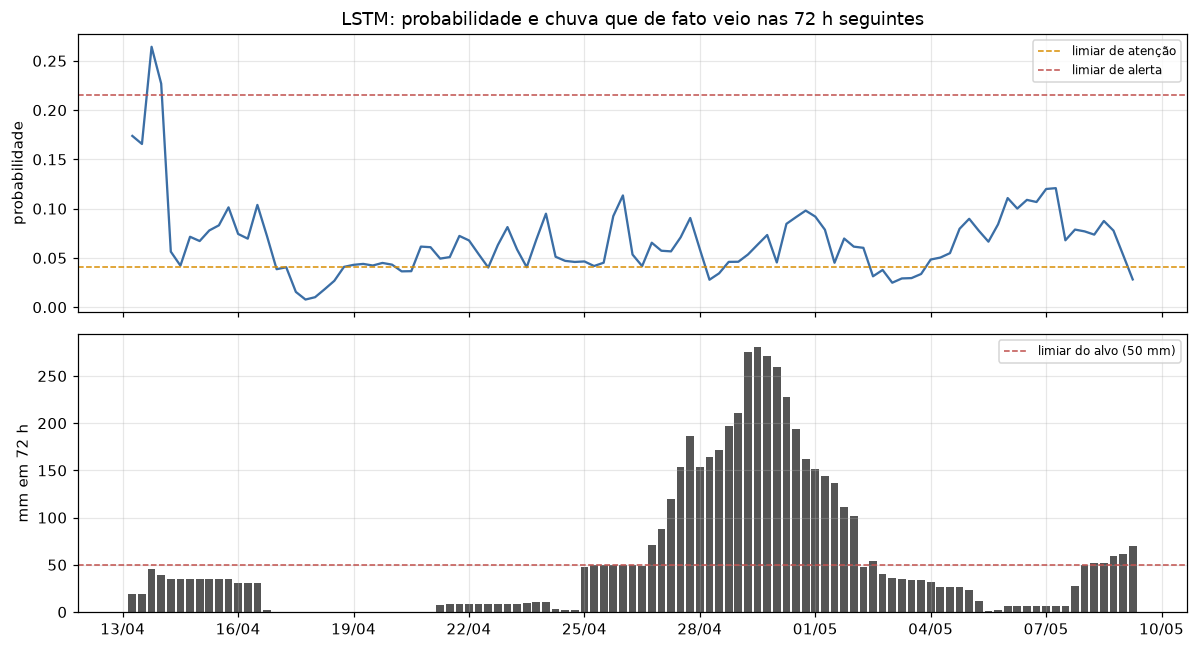

In [21]:
centro = eps.sort_values("pico de chuva em 72 h (mm)", ascending=False).iloc[0]["início"]
jan = slice(centro - pd.Timedelta(days=12), centro + pd.Timedelta(days=14))
fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axs[0].plot(prob_t.loc[jan].index, prob_t.loc[jan].values, color="#3b6ea5")
axs[0].axhline(LIM_ATENCAO, color="#d98e04", ls="--", lw=1, label="limiar de atenção")
axs[0].axhline(LIM_ALERTA, color="#c0504d", ls="--", lw=1, label="limiar de alerta")
axs[0].set_ylabel("probabilidade"); axs[0].legend(fontsize=8)
axs[0].set_title(f"{ARQ_FINAL}: probabilidade e chuva que de fato veio nas 72 h seguintes")
axs[1].bar(fut_t.loc[jan].index, fut_t.loc[jan].values, width=0.2, color="#555")
axs[1].axhline(LIMIAR_MM, color="#c0504d", ls="--", lw=1, label=f"limiar do alvo ({LIMIAR_MM} mm)")
axs[1].set_ylabel("mm em 72 h"); axs[1].legend(fontsize=8)
axs[1].xaxis.set_major_locator(mdates.DayLocator(interval=3))
axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
plt.tight_layout(); plt.show()

### Leitura da demonstração

A regra de escolha (maior PR-AUC de validação, média de três sementes) apontou a LSTM, com 0,097 contra 0,094 da GRU, diferença dentro do desvio (0,009 a 0,011). Foi a rede com a menor PR-AUC no teste entre as três, e a regra não foi mudada depois de ver isso.

Nas 24 horas até o início de cada um dos 29 episódios do teste, a LSTM chegou a alerta em 2, a atenção em 21 e ficou em baixo em 6. Os exemplos mostram o mesmo quadro. O episódio de 15/06/2025 é um acerto claro: probabilidade de 0,28, alerta, com apenas 2,2 mm nas 72 horas anteriores, ou seja, a rede previu a chuva sem chuva anterior. No maior episódio do teste (25/04/2024, 280 mm em 72 horas), a probabilidade fica em 0,04 e 0,05, e a faixa é atenção só porque o limiar de atenção é baixo (0,041). Em 08/06/2023 também só atenção. O pior alarme falso (09/09/2024, probabilidade 0,51, sem chuva nas 72 horas anteriores e 2,0 mm nas seguintes) mostra que a rede pode disparar alto sem motivo visível nas variáveis resumidas da tabela.

Na linha do tempo de abril de 2024, a probabilidade fica entre 0,02 e 0,12 durante todo o evento e não sobe antes da chuva. O único cruzamento do limiar de alerta no gráfico é em 13 e 14/04 (0,26), uma semana e meia antes, sem evento forte (as barras ficam abaixo de 50 mm). A rede não antecipa esse episódio.

### Integração com a solução: simulação funcional

Para entrar no Marca d'Água, a rede precisa de uma função que receba as últimas 72 horas e devolva probabilidade e faixa. A função abaixo faz isso e é chamada com uma janela real do teste, montada no formato que uma API receberia (um JSON com as 72 horas). Isto é uma simulação: ela roda neste notebook e não está ligada à API nem à Lambda.

In [22]:
def prever(janela, data_hora):
    """janela: DataFrame com 72 linhas (uma por hora) e as colunas de CANAIS, nas unidades originais."""
    a = janela[CANAIS].to_numpy(dtype="float64").copy()
    a[:, 0] = np.log1p(np.nan_to_num(a[:, 0]))
    a = np.nan_to_num(np.clip((a - mu) / dp, -5, 5), nan=0.0).astype("float32")[None]
    d = pd.Timestamp(data_hora).dayofyear
    s = np.array([[np.sin(2 * np.pi * d / 365.25), np.cos(2 * np.pi * d / 365.25)]], dtype="float32")
    p = float(np.mean([m.predict([a, s], verbose=0).ravel()[0] for m in final[ARQ_FINAL]["modelos"]]))
    return {"probabilidade": round(p, 3), "faixa": str(faixa(p))}

exemplo = momentos[0][0]
janela = bruto.loc[exemplo - pd.Timedelta(hours=JANELA_H - 1):exemplo]
corpo = {"dispositivo_id": "MD-POA-001", "data_hora": f"{exemplo:%Y-%m-%dT%H:%M}Z",
         "janela_72h": {c: [None if np.isnan(v) else round(float(v), 1) for v in janela[c]] for c in CANAIS}}
print("entrada (resumo do JSON):", {k: (v if k != "janela_72h" else f"{len(v['chuva_mm'])} horas x {len(v)} variáveis") for k, v in corpo.items()})
print("saída:", prever(pd.DataFrame(corpo["janela_72h"]), corpo["data_hora"]))

entrada (resumo do JSON): {'dispositivo_id': 'MD-POA-001', 'data_hora': '2024-04-25T06:00Z', 'janela_72h': '72 horas x 6 variáveis'}
saída: {'probabilidade': 0.042, 'faixa': 'atenção'}


A simulação mostra o caminho completo: a função recebe 72 horas, aplica a mesma escala do treino (`log1p` na chuva, padronização e corte), roda as 3 redes do conjunto e devolve probabilidade e faixa. Na solução, a API ou a Lambda receberia o JSON, chamaria `prever` e gravaria a faixa junto da ocorrência, para um painel mostrar atenção ou alerta além do nível medido. O nó e o LED continuam avisando pelos limiares de nível, sem depender da rede neural.

O que falta desenvolver, e fica como evolução futura:

- Pressão, vento e rajada não são medidos pelo nó. Seria preciso buscá-los na estação do INMET em tempo quase real ou treinar de novo só com o que o nó mede (chuva, temperatura e umidade).
- Empacotar e servir o modelo. O TensorFlow é pesado para uma função Lambda, e o caminho seria TensorFlow Lite, ONNX ou um serviço próprio.
- Guardar a janela das últimas 72 horas de cada nó, porque hoje o nó envia leituras isoladas.
- Monitorar o desempenho em uso real e treinar de novo com os eventos novos.

## 10. Acessibilidade, segurança, proteção de dados e sustentabilidade

Acessibilidade. A saída é uma faixa de três níveis, pensada para sair pelos mesmos canais do nó: LED (piscando em atenção, aceso em alerta) e bipes distintos (um em atenção, três em alerta) para quem não enxerga, além de texto curto para uma mensagem futura. A ligação da faixa do modelo ao LED e ao buzzer não está implementada. Hoje eles seguem os limiares de nível e de chuva.

Segurança. A rede só recebe números de sensores, sem texto livre, então não tem a superfície de injeção que o relato do morador tem. A entrada é limitada a ±5 desvios, o que reduz o efeito de um valor absurdo. O risco que sobra é uma leitura forjada alterar a previsão, e as proteções previstas para a API estão em `ciberseguranca/inventario-ameacas.md`.

Proteção de dados. Os dados do INMET são públicos, e a janela de entrada do nó é telemetria sem dado pessoal.

Sustentabilidade. As redes têm de 4 mil a 30 mil parâmetros e treinam em CPU. A execução completa deste notebook, com 57 treinos, levou cerca de 30 minutos em um computador comum, sem GPU. Modelos desse tamanho cabem em um serviço pequeno e, no futuro, em um dispositivo de borda.

Condições reais de uso. A internet cai durante a enchente. Por isso a faixa do modelo é um sinal complementar, e o aviso local do nó não depende dela.

## 11. Documentação: decisões, resultados, limitações e evolução

Decisões técnicas. Janela de 72 horas, igual ao horizonte do alvo, com uma amostra a cada 6 horas. Chuva em `log1p`, padronização com estatísticas do período de ajuste e corte em ±5 desvios. Divisão temporal em ajuste, validação e teste, com 72 horas de folga entre as partes. Perda de entropia cruzada sem peso de classe e bias de saída na taxa de eventos, para a probabilidade fazer sentido como probabilidade. PR-AUC como métrica de parada e de comparação. Três redes (MLP, GRU e LSTM) avaliadas com três sementes cada e usadas como conjunto. A validação escolhe, o teste aparece uma vez.

Resultados. Com regularização, as três redes ficam acima do acaso na validação e no teste, mas sem vantagem sobre uma regressão logística na mesma entrada: PR-AUC de teste de 0,150 a 0,189 para as redes e 0,194 para a regressão logística, contra 0,084 do acaso. As diferenças entre os modelos cabem nos intervalos de confiança. O resultado é parecido com o do notebook de ML, onde a regressão logística sobre atributos resumidos chegou a 0,203 em um recorte de teste quase igual (4.162 amostras aqui, 4.302 lá, por causa do filtro de janela incompleta).

Limitações. O sinal é fraco e o ganho sobre o acaso é pequeno e instável de um ano para o outro. A validação tem 124 eventos e o teste tem 29 episódios independentes, de uma estação só. O alvo (chuva acumulada em 72 horas) aproxima o risco de alagamento e não o mede. O modelo não antecipou o maior episódio do teste. Os números deste notebook são os de uma execução com `SEED = 42` no TensorFlow 2.21 e podem mudar na terceira casa em outra máquina ou versão.

Evolução futura, nada disso implementado:

- Previsão numérica de tempo como entrada, que é o que de fato traz antecedência.
- Mais estações e mais anos, para ter mais episódios na validação e no teste.
- Calibrar as probabilidades antes de definir as faixas.
- Busca de hiperparâmetros com um algoritmo genético no lugar da busca aleatória, com a validação temporal como função de aptidão.
- Testar uma CNN 1D e técnicas de explicação (atribuição por gradientes) para saber quais horas da janela a rede usa.
- Treinar só com as variáveis que o nó mede, para ligar o modelo ao dispositivo sem depender de outra fonte.